#### Retail Customer Satisfaction Insights

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
# Load Dataset

df = pd.read_csv("customer_satisfaction_data.csv")

print(df.head())

print(df.info())

print(df.tail())

print(df.describe)

print(df.columns)

print(df.dtypes)

print(df.shape)

   Survey_ID  Customer_ID Store_Location  Visit_Date  Purchase_Amount  \
0          1         1628       Downtown  2025-06-08              384   
1          2         1069    City Center  2025-04-01              120   
2          3         1243      Mall Road  2025-04-27              104   
3          4         1396   Suburb Plaza  2025-03-24              110   
4          5         1468   Suburb Plaza  2025-06-20              208   

   Wait_Time_Min  Staff_Rating  Product_Rating  Cleanliness_Rating Recommend  \
0              8             2               2                   1        No   
1             24             1               2                   4        No   
2             25             5               1                   4       Yes   
3             15             1               3                   1        No   
4              8             1               4                   3        No   

   Total_Rating  
0           1.7  
1           2.3  
2           3.3  
3       

In [3]:
# Convert visit_date to datetime

df['Visit_Date'] = pd.to_datetime(df['Visit_Date'])

df['Month'] = df['Visit_Date'].dt.month_name()

df['Weekday'] = df['Visit_Date'].dt.day_name()

print(df[['Visit_Date' , 'Month' , 'Weekday']].head())

  Visit_Date  Month  Weekday
0 2025-06-08   June   Sunday
1 2025-04-01  April  Tuesday
2 2025-04-27  April   Sunday
3 2025-03-24  March   Monday
4 2025-06-20   June   Friday


#### Replace rating (1-5) with descriptive categories using Numpy/Pandas: Low , Medium , High.

In [6]:
# Low = 1/2
# Medium = 3
# High = 4/5

def rating_calculation(rating):
    if rating <= 2:
        return 'Low'
    elif rating == 3:
        return 'Medium'
    else:
        return 'High'

# staff Rating

df['Staff_Rating_Calculation'] = df['Staff_Rating'].apply(rating_calculation)

# Product_Rating

df['Product_Rating_Calculation'] = df['Product_Rating'].apply(rating_calculation)

# Cleanliness_Rating

df['Cleanliness_Rating_Calculation'] = df['Cleanliness_Rating'].apply(rating_calculation)

print(df[[
    "Staff_Rating",
    "Staff_Rating_Calculation",
    "Product_Rating",
    "Product_Rating_Calculation",
    "Cleanliness_Rating",
    "Cleanliness_Rating_Calculation"
]].head())



   Staff_Rating Staff_Rating_Calculation  Product_Rating  \
0             2                      Low               2   
1             1                      Low               2   
2             5                     High               1   
3             1                      Low               3   
4             1                      Low               4   

  Product_Rating_Calculation  Cleanliness_Rating  \
0                        Low                   1   
1                        Low                   4   
2                        Low                   4   
3                     Medium                   1   
4                       High                   3   

  Cleanliness_Rating_Calculation  
0                            Low  
1                           High  
2                           High  
3                            Low  
4                         Medium  


#### Calculation average Total_Rating by Store_Location

In [7]:
location_rating = df.groupby('Store_Location')['Total_Rating'].mean()

print(location_rating)

Store_Location
City Center     2.697727
Downtown        2.912500
Mall Road       3.017021
Suburb Plaza    3.057377
Name: Total_Rating, dtype: float64


#### Analyze the correlation between Wait_Time_Min and Purchase_Amount


In [9]:
correlation = np.corrcoef(df['Wait_Time_Min'] , df['Purchase_Amount'])[0 , 1]

print("Correlation:" , round(correlation , 2))

Correlation: 0.13


#### Find whoch day of the wek has the highest total purchases

In [10]:
day_purchase = df.groupby("Weekday")["Purchase_Amount"].sum()

highest_day = day_purchase.idxmax()

highest_amount = day_purchase.max()

print("Day:" , highest_day)

print("Amount:" , highest_amount)

Day: Monday
Amount: 6938


#### Determine how many customers recommend teh store from each location

In [11]:
recommendation = df[df['Recommend'] == "Yes"].groupby(["Store_Location"]).size()

print(recommendation)

Store_Location
City Center     20
Downtown        29
Mall Road       27
Suburb Plaza    38
dtype: int64


#### Plot a bar chart of average ratings by store location

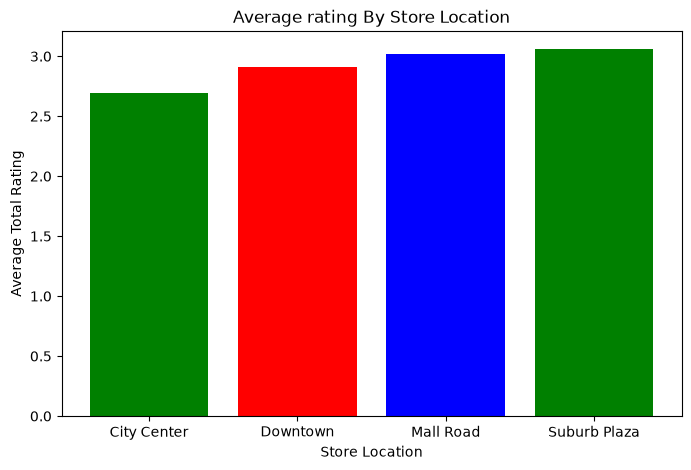

In [14]:
plt.figure(figsize=(8 , 5))

plt.bar(
    location_rating.index,
    location_rating.values,
    color=["green" , "red" , "blue"]
)

plt.title("Average rating By Store Location")

plt.xlabel("Store Location")

plt.ylabel("Average Total Rating")

plt.show()

#### Create a pie chart for recommendation distribution

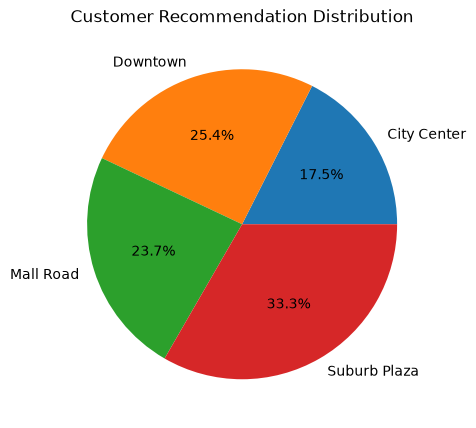

In [16]:
plt.figure(figsize=(5 , 6))

plt.pie(
    recommendation.values,
    labels=recommendation.index,
    autopct="%1.1f%%"
)

plt.title("Customer Recommendation Distribution")

plt.show()

#### Plot a line chart of total purchases over time

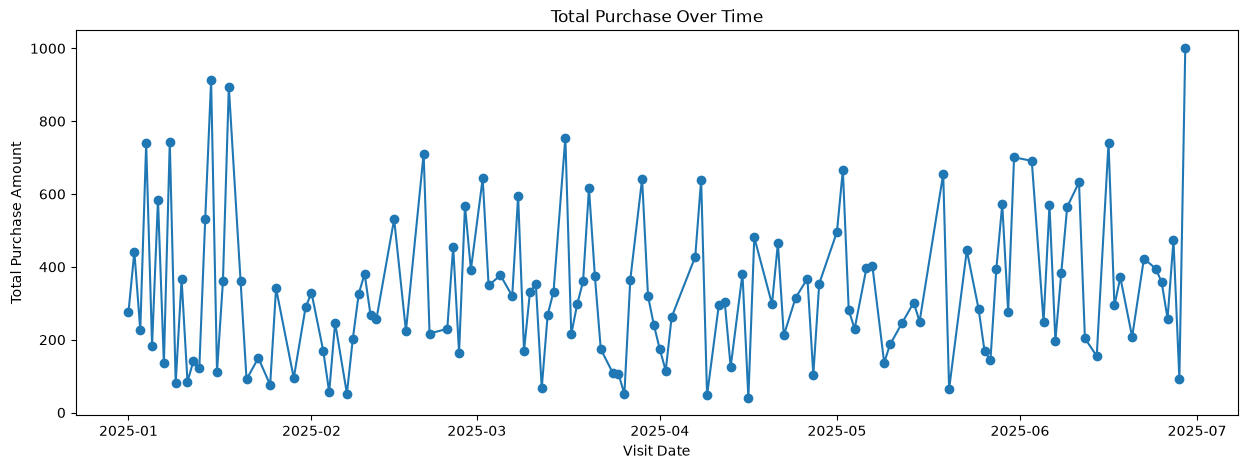

In [17]:
daily_purchase = df.groupby(
    "Visit_Date"
)["Purchase_Amount"].sum()

plt.figure(figsize=(15 , 5))

plt.plot(
    daily_purchase.index,
    daily_purchase.values,
    marker="o"
)

plt.title("Total Purchase Over Time")

plt.xlabel("Visit Date")

plt.ylabel("Total Purchase Amount")

plt.show()